# Part 1: Baseline Discrete Local Search - Hill Climber

### Problem formulation

We choose a subset of n candidate AI models to deploy on an edge platform. A decision vector x in {0,1}^n encodes the choice (1 = deploy, 0 = skip).
The objective is to maximise the total utility f(x) = sum p_j * x_j subject to the resource capacities sum r_ij * x_j <= b_i for every resource i = 1..m.

For n = 28 this is about 268 million states. I use a fixed evaluation budget rather than enumerating all subsets.

In [2]:
import numpy as np
from workload_data_loader import load_workload_instance

n1,m1,u1,d1,c1=load_workload_instance("multi_resource_n28_m2.txt")

print(f"Instance 1:the number of models={n1},the number of capacities={m1},utilities.shape={u1.shape},demands.shape={d1.shape},capacity={c1} ")

print("utillity:")
print(u1)

print("demand:")
print(d1)

print("capacity:")
print(c1)

Instance 1:the number of models=28,the number of capacities=2,utilities.shape=(28,),demands.shape=(2, 28),capacity=[500. 500.] 
utillity:
[ 1898.   440. 22507.   270. 14148.  3100.  4650. 30800.   615.  4975.
  1160.  4225.   510. 11880.   479.   440.   490.   330.   110.   560.
 24355.  2885. 11748.  4550.   750.  3720.  1950. 10500.]
demand:
[[ 45.   0.  85. 150.  65.  95.  30.   0. 170.   0.  40.  25.  20.   0.
    0.  25.   0.   0.  25.   0. 165.   0.  85.   0.   0.   0.   0. 100.]
 [ 30.  20. 125.   5.  80.  25.  35.  73.  12.  15.  15.  40.   5.  10.
   10.  12.  10.   9.   0.  20.  60.  40.  50.  36.  49.  40.  19. 150.]]
capacity:
[500. 500.]


### Checking a candidate solution

‘usage’ calculates how much of each resource the selected models consume. ‘is_feasible’ checks every resource against its capacity, while ‘total_utility’ adds the utilities of the selected models. I keep these checks separate because a high utility is only useful if the corresponding selection can actually be deployed. The GA in Part 2 reuses the same definitions.

In [3]:
# Helper function
import random

def usage(current_x, demands):
    m,n=demands.shape
    used=[]
    for i in range(m):
        s=0.0
        for j in range(n):
            s+=demands[i,j]*current_x[j]
        used.append(s)
    return used
    
def is_feasible(current_x,demands,capacities):
    m,n=demands.shape
    for i in range(m):
        resource_total=0

        for j in range(n):
            resource_total+=demands[i,j]*current_x[j]

        if resource_total>capacities[i]:
            return False
    return True

def total_utility(current_x, utility):
    total=0.0
    for i in range(len(current_x)):
        total+=utility[i]*current_x[i]
        
    return total

### Encoding and neighbourhood

Each bit represents one model: 1 means deploy it and 0 means skip it. To generate a neighbour, I copy the current selection and flip three distinct bits chosen at random. This allows one proposal, for example, to remove one selected model and add two others. Such a move is useful under capacity limits because removing a model can free resources for a different combination.

The three flips define the proposed move. Repair and refill may make further changes before the candidate is evaluated.

In [5]:
def get_neighbor_multibit(x, k=3):
    x_new=x.copy()
    indices=np.random.choice(len(x_new), size=k, replace=False)

    for idx in indices:
        x_new[idx]=1-x_new[idx]

    return x_new

### Constraint handling

A move can create an invalid solution. I use repair because the hardware capacities are hard limits. Repair allows an over-capacity proposal to contribute a feasible selection, while keeping fitness directly interpretable as deployment utility without choosing a penalty weight. We use a repair strategy with two phases. First, drop: repeatedly remove the selected item with the lowest utility-per-resource-burden ratio until the solution is feasible, where the burden of item j is sum_i r_ij / b_i (dividing by capacity makes resources with different units comparable). Second, re-add: greedily add excluded items back in decreasing ratio order if they still fit. The
re-add phase turns repair into an improvement step.

In [7]:
#only delete
def repair(current_x, utilities, demands, capacities):
    x_repaired=current_x.copy()

    while not is_feasible(x_repaired, demands, capacities):
        selected_indices = []

        for j in range(len(x_repaired)):
            if x_repaired[j] == 1:
                selected_indices.append(j)

        if len(selected_indices) == 0:
            break

        worst_index = None
        worst_ratio = float("inf")

        for j in selected_indices:
            total_burden = 0

            for i in range(len(capacities)):
                total_burden+=demands[i, j]/capacities[i]

            ratio=utilities[j]/(total_burden + 1e-6) #ratio bigger,the situation better.

            if ratio<worst_ratio:
                worst_ratio=ratio
                worst_index=j

        x_repaired[worst_index]=0 # delete the worst one

    return x_repaired   
    
def repair_and_improve(current_x,utilities,demands,capacities):
    xr=repair(current_x, utilities,demands,capacities)  

    out=[]
    for j in range(len(xr)):
        if xr[j]==0:
            burden=0.0
            for i in range(len(capacities)):
                burden+=demands[i,j]/capacities[i]
            ratio=utilities[j]/(burden+1e-6)
            out.append((ratio,j))
    
    out.sort(reverse=True)#

    used=usage(xr, demands)#
    for ratio, j in out:
        fits=True
        for i in range(len(capacities)):
            if used[i]+demands[i,j]>capacities[i]:
                fits = False
                break
        if fits:
            xr[j]=1
            for i in range(len(capacities)):
                used[i]=used[i]+demands[i, j]

    return xr

### Hill climbing and evaluation protocol

Each run starts from a random binary selection. I repair and refill it before evaluating it. At each subsequent step, I generate one three-bit neighbour, repair and refill it, and accept it only if its utility is strictly higher than the current utility. Repair and refill can change additional bits, so the candidate finally evaluated may differ from the current solution in more or fewer than three positions.Random starts let the runs explore different starting selections. Strict acceptance makes this a simple baseline: utility seldom decreases, but the search cannot reach a better solution through an intermediate move of equal or lower utility.

I run the algorithm 30 times using seeds 42–71, with 5,000 fitness evaluations per run. The first evaluation scores the initial solution. Every later evaluation scores one candidate, including candidates that are rejected. I record the best utility after every evaluation so that runs can be compared at the same search budget.

In [9]:
def hill_climbing(utilities,demands,capacities,max_evals,
                  neighbor_operator=get_neighbor_multibit,repair=repair_and_improve):
    n = len(utilities)

    current_x=[random.randint(0, 1) for _ in range(n)]
    current_x=repair(current_x, utilities, demands, capacities)
    current_utility=total_utility(current_x, utilities)

    best_x=current_x.copy()
    best_utility=current_utility

    history=[best_utility]

    evaluations=1

    while evaluations<max_evals:
        neighbor=neighbor_operator(current_x)
        neighbor=repair(neighbor, utilities, demands, capacities)
        neighbor_utility=total_utility(neighbor, utilities)

        evaluations+=1

        if neighbor_utility > current_utility:
            current_x = neighbor.copy()
            current_utility = neighbor_utility

        if current_utility > best_utility:
            best_x = current_x.copy()
            best_utility = current_utility

        history.append(best_utility)

    return best_x, best_utility, history

In [10]:
all_scores=[]
all_histories=[]
all_solutions=[]
all_seeds=[]

num_runs = 30

for run_id in range(num_runs):

    seed=42+run_id

    # Fix both random number generators
    random.seed(seed)
    np.random.seed(seed)

    best_x,best_utility,history=hill_climbing(u1,d1,c1,5000)

    all_scores.append(best_utility)
    all_histories.append(history)
    all_solutions.append(best_x)
    all_seeds.append(seed)

print("Number of runs:",len(all_scores))
print("Seeds used:",all_seeds)

Number of runs: 30
Seeds used: [42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71]


In [11]:
print("Mean utility:", np.mean(all_scores))
print("Median utility:", np.median(all_scores))
print("Standard deviation:", np.std(all_scores, ddof=1))
print("Best utility:", max(all_scores))
print("Worst utility:", min(all_scores))

# Check feasibility of every final solution
feasibility_results=[
    is_feasible(x, d1, c1)
    for x in all_solutions
]

feasible_count=sum(feasibility_results)

print("Feasible solutions:",feasible_count, "/", num_runs)
print("Feasibility rate:",feasible_count/num_runs * 100, "%")

Mean utility: 130883.0
Median utility: 130883.0
Standard deviation: 0.0
Best utility: 130883.0
Worst utility: 130883.0
Feasible solutions: 30 / 30
Feasibility rate: 100.0 %


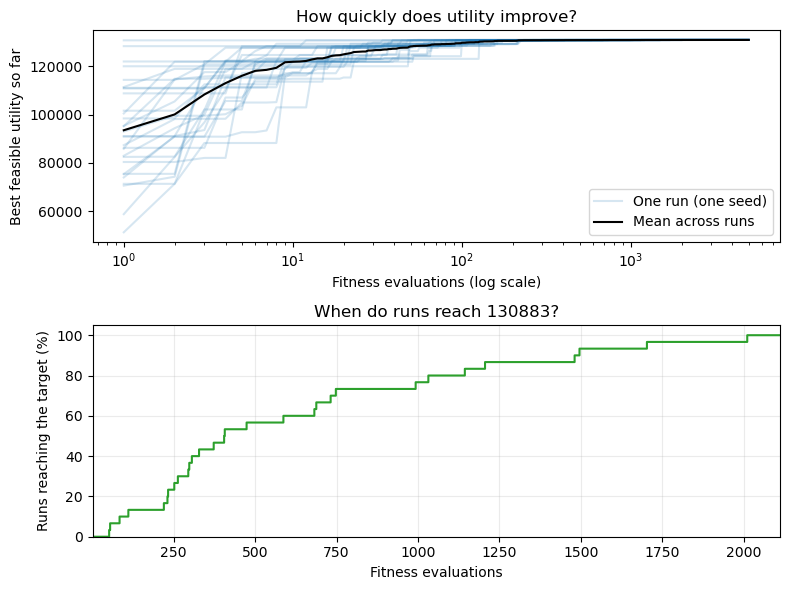

In [12]:
import matplotlib.pyplot as plt

hc_histories=np.asarray(all_histories)
evaluations=np.arange(1,hc_histories.shape[1]+1)
target=hc_histories[:,-1].max()

reached=hc_histories>=target
attainment=100*reached.mean(axis=0)
first_hits=evaluations[reached[reached.any(axis=1)].argmax(axis=1)]

fig,axes=plt.subplots(2, 1, figsize=(8, 6))

for index,run_history in enumerate(hc_histories):
    axes[0].plot(
        evaluations, run_history,color="tab:blue",alpha=0.18,
        label="One run (one seed)" if index == 0 else None
    )

axes[0].plot(evaluations, hc_histories.mean(axis=0),
             color="black", label="Mean across runs")
axes[0].set_xscale("log")
axes[0].set_xlabel("Fitness evaluations (log scale)")
axes[0].set_ylabel("Best feasible utility so far")
axes[0].set_title("How quickly does utility improve?")
axes[0].legend()

axes[1].step(evaluations, attainment, where="post", color="tab:green")
axes[1].set_xlim(1, first_hits.max() * 1.05)
axes[1].set_ylim(0, 105)
axes[1].set_xlabel("Fitness evaluations")
axes[1].set_ylabel("Runs reaching the target (%)")
axes[1].set_title(f"When do runs reach {target:.0f}?")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [14]:
first_hit = [
    next(i for i, score in enumerate(history, start=1) if score == max_score)
    for history, max_score in zip(all_histories, all_scores)
]

print("Evaluations to first reach each run's final best:")
print("Minimum:", min(first_hit))
print("Median:", np.median(first_hit))
print("Maximum:", max(first_hit))

Evaluations to first reach each run's final best:
Minimum: 52
Median: 406.0
Maximum: 2011


### Baseline results: final quality and time to target

All 30 runs returned feasible solutions with final utility **130,883**. The mean, median, minimum and maximum were therefore all 130,883, and the sample standard deviation was zero. The sample standard deviation of final utility was zero because all 30 runs finished at 130,883. However,the number of evaluations needed to first reach this value ranged from 52 to 2,011. This shows consistent final utility across these seeds; it does not prove that the utility is globally optimal or that every run selected exactly the same models.

In the upper plot, each pale blue line is one run and the black line is the mean best utility at each evaluation. The lower plot shows the percentage of runs that had reached 130,883 by each evaluation. I use 130,883 as the best value observed in this experiment, not as a known optimum.

The difference between runs was **how quickly they reached the target**. The first run to reach it needed 52 evaluations, the median first-hit time was 406 evaluations, and the slowest run needed 2,011. All runs had therefore reached their final best well before the 5,000-evaluation budget ended.

# Part 2 Advanced Metaheuristic Engineering
### Why a genetic algorithm

Instance 2 has the same structure as a multidimensional 0–1 knapsack problem. Each model is an item that can be selected or skipped, its utility is the benefit of selecting it, and its demands count against five separate hardware capacities. A 90-bit chromosome therefore represents a deployment decision directly: each bit says whether one model is selected. I chose a genetic algorithm because it can maintain several candidate subsets and use crossover to combine parts of two selections. Chu and Beasley (1998, p. 63) used a genetic algorithm to tackle the multidimensional knapsack problem. My model-selection task has the same structure: each model is either selected or skipped, and its resource demands count against several capacity limits.

In my implementation, that information is each model's utility and its share of the available resources. Even if both parents are feasible, a child can inherit resource-intensive models from both and exceed a capacity. After crossover and mutation, I therefore apply the repair-and-refill rule from Part 1. I divide each resource demand by its capacity and sum these fractions to measure a model's burden. If the child is infeasible, I remove selected models with the lowest utility relative to that burden until all five limits are satisfied. I then try to add excluded models in decreasing ratio order, accepting each addition only if it fits. This lets me score the repaired child by its actual deployment utility.

In [16]:
n2,m2,u2,d2,c2 = load_workload_instance("multi_resource_n90_m5.txt")
print(f"Instance 2:the number of models={n2},the number of capacities={m2},utilities.shape={u2.shape},demands.shape={d2.shape},capacity={c2}")

Instance 2:the number of models=90,the number of capacities=5,utilities.shape=(90,),demands.shape=(5, 90),capacity=[2100. 1100. 3300. 3700. 3600.]


### GA components and design choices

- **Initialisation.** I generate 50 random binary selections. Each one is repaired and refilled, then three distinct bits are flipped and feasibility is restored again. The first step constructs a feasible selection with some utility; the three-bit perturbation is intended to introduce variation before selection begins. I did not separately test the effect of this perturbation.After the three flips, I repair capacity violations without refilling again. A second greedy refill could immediately add back a model that the perturbation had just removed.
- **Parent selection.** A binary tournament draws two candidates and returns the one with higher fitness. This favours better candidates without requiring every parent to be the current best individual.
- **Crossover.** The baseline GA uses single-point crossover with probability 0.9. It takes a prefix from one parent and a suffix from the other. If crossover is skipped, the parents are copied, but the copies still go through mutation and repair.I use a single cut as a simple baseline because it preserves a contiguous segment from each parent. Part 3 then tests whether transferring an internal segment with two cuts is more useful for this model ordering.
- **Mutation.** Each bit flips independently with probability 1/90. A child therefore has one expected flip, although the actual number may be zero or more than one. If both parents skip a model, crossover alone cannot select it in their child, but mutation can flip that model's bit from 0 to 1.
- **Constraint handling.** A child of two feasible parents can still violate a resource limit. After mutation, I count whether the child is infeasible, then repair and refill it before scoring it. This distinguishes the feasibility of the children initially produced from the feasibility of the solutions admitted to the population.

I used 50 individuals and a crossover probability of 0.9 as fixed settings for the comparison; I did not tune these values or establish that they are optimal.

In [18]:
#Helper function

def cal_fitness(current_x,utilities):
    return total_utility(current_x,utilities)
    
#the pop_size usually is 50
def initial_population(utilities,demands,capacities,pop_size,kick=3):
    n=len(utilities)
    population=[]
    fitness=[]
    for _ in range(pop_size):
        #randomly create a situation
        born=np.random.randint(0,2,n)
        #do the repair
        born=repair_and_improve(born,utilities,demands,capacities)
        #kick
        indices=np.random.choice(n,size=kick,replace=False)
        for idx in indices:
            born[idx]=1-born[idx]
            
        born=repair(born,utilities,demands,capacities)
        fitness.append(cal_fitness(born,utilities))
        population.append(born)

    return population,fitness  

#choose parents
def tournament_selection(population,fitness,k=2):
    best_i=int(np.random.randint(len(population)))
    for _ in range(k-1):
        i=int(np.random.randint(len(population)))
        if fitness[i]>fitness[best_i]:
            best_i=i 
    return best_i

#crossover
def single_point_crossover(parent_a,parent_b):
    cut = int(np.random.randint(1, len(parent_a)))     
    child1 = np.concatenate([parent_a[:cut], parent_b[cut:]])
    child2 = np.concatenate([parent_b[:cut], parent_a[cut:]])
    return child1, child2
    
#bit-flip mutation
def mutate(x, p_mut):
    for j in range(len(x)):
        if np.random.random() < p_mut:     
            x[j]=1-x[j]
    return x

### Elitism and evaluation counting

The best individual enters the next generation unchanged. Its fitness is already known, so copying it does not consume another evaluation. The initial population uses 50 evaluations; the rest of the 10,000-evaluation budget is spent on newly scored children.

Before evaluating a child, I check that both a population place and an evaluation remain. This matters because crossover produces two children, but sometimes only one place is available. The best solution and its history are updated after each evaluation, including evaluations in the final incomplete generation.

In [19]:
def genetic_algorithm(utilities, demands, capacities,
                      pop_size=50,max_evals=10000,p_cross=0.9,
                      crossover=single_point_crossover):
    
    p_mut=1.0/len(utilities)                   
    population,fitness=initial_population(utilities,demands,capacities,pop_size)
    evals=pop_size                   
    best_x=population[0].copy()
    best_utility=fitness[0]
    history=[]

    for index, score in enumerate(fitness):
        if score>best_utility:
            best_x=population[index].copy()
            best_utility=score
        history.append(best_utility)

    infeasible_count=0

    while evals<max_evals:
        elite_i=fitness.index(max(fitness))
        new_pop=[population[elite_i].copy()]
        new_fit=[fitness[elite_i]] # create new_fit as a list to keep the data strategy

        while len(new_pop)<pop_size and evals<max_evals:
            i1=tournament_selection(population,fitness)   #choose parents
            i2=tournament_selection(population,fitness)
            if np.random.random()<p_cross:                 # 90% pobability to crossover
                child1, child2 = crossover(population[i1], population[i2])  
            else:                                            # otherwise clone
                child1=population[i1].copy()
                child2=population[i2].copy()
                
             
            for child in (child1,child2):
                if len(new_pop)==pop_size or evals==max_evals:
                    break
                child=mutate(child, p_mut)

                if not is_feasible(child, demands, capacities):
                    infeasible_count+=1

                child=repair_and_improve(child, utilities, demands, capacities)
                score=cal_fitness(child, utilities)
                evals+=1

                if score>best_utility:
                    best_x=child.copy()
                    best_utility = score

                history.append(best_utility)
                new_pop.append(child)
                new_fit.append(score)

        population,fitness=new_pop,new_fit
        
    return best_x,best_utility,history,infeasible_count

seed 42:best=11187 feasible=True
seed 43:best=11191 feasible=True
seed 44:best=11187 feasible=True
seed 45:best=11191 feasible=True
seed 46:best=11187 feasible=True
seed 47:best=11191 feasible=True
seed 48:best=11191 feasible=True
seed 49:best=11187 feasible=True
seed 50:best=11187 feasible=True
seed 51:best=11191 feasible=True
mean=11189.0  best=11191  worst=11187


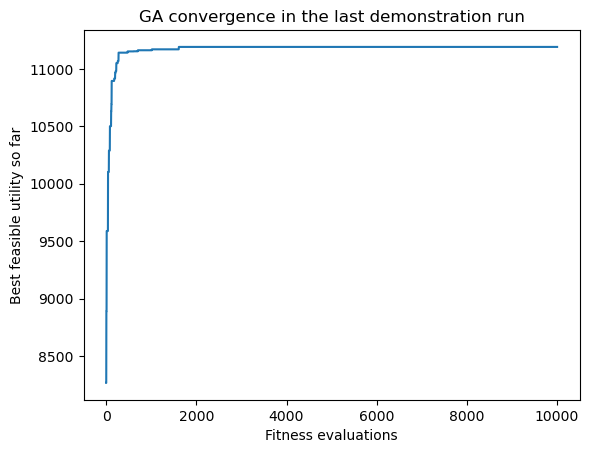

In [20]:
ga_scores=[]
for run_id in range(10):
    seed=42+run_id
    random.seed(seed)
    np.random.seed(seed)
    best_x,best_f,history,infeasible_count=genetic_algorithm(u2, d2, c2)
    ga_scores.append(best_f)
    print(f"seed {seed}:best={best_f:.0f} feasible={is_feasible(best_x, d2, c2)}")
ga_results=np.array(ga_scores)
print(f"mean={ga_results.mean():.1f}  best={ga_results.max():.0f}  worst={ga_results.min():.0f}")

plt.plot(range(1,len(history) + 1),history)
plt.xlabel("Fitness evaluations")
plt.ylabel("Best feasible utility so far")
plt.title("GA convergence in the last demonstration run")
plt.show()

### Single-point GA results on Instance 2

I ran the single-point GA with seeds 42–51 on the larger instance. All ten final solutions were feasible. Five runs finished at 11,187 and five finished at 11,191, giving a mean final utility of **11,189.0**.

The figure shows the last demonstration run, seed 51. Its best feasible utility increased early and then remained at 11,191 for the rest of the budget. A flat line means that later evaluations did not improve the best score; it does not mean that the algorithm stopped generating children or that 11,191 is globally optimal.

These ten seeds are included in the larger experiment below. They illustrate the baseline GA and are not counted as ten additional independent runs in Part 3.

# Part 3 Empirical Study & Hypothesis Testing
### Variant selection and research hypothesis

We compare two crossover operators: single-point vs multi-point (two-point) crossover, inside the same GA, on Instance 2.

Experimental design and hypothesis: On Instance 2, I compare single-point and two-point crossover. Two-point crossover can copy an internal segment from one parent while retaining both ends of the other parent. I expect this additional mixing to give two-point crossover more wins, although the benefit may be limited if neighbouring model indices do not represent useful groups.

Each variant uses the same 30 seeds, population size of 50, crossover probability of 0.9, mutation probability of 1/90, repair rule, and budget of 10,000 fitness evaluations. Each seed defines one pair of runs with the same initial population. The primary outcome is the final best feasible utility.

I use a two-sided paired sign test at the 0.05 significance level. The null hypothesis is that either variant is equally likely to win a non-tied pair. I also report the mean paired utility difference to show the size and direction of the difference.

In [23]:
def two_point_crossover(parent_a,parent_b):
    c1, c2=sorted(np.random.choice(range(1,len(parent_a)),size=2,replace=False))
    child1=np.concatenate([parent_a[:c1],parent_b[c1:c2],parent_a[c2:]])
    child2=np.concatenate([parent_b[:c1],parent_a[c1:c2],parent_b[c2:]])
    return child1, child2

### Controlled comparison

I compare the two variants across 30 paired runs using seeds 42–71. For each seed, I reset the random generators before each variant starts, giving the two variants the same initial population. Both use a population of 50, binary tournament selection, crossover probability 0.9, mutation probability 1/90, one elite, the same repair rule and a budget of 10,000 fitness evaluations. Only the crossover operator changes.

For each run, I record the final score, best-so-far history, elapsed time and number of children that are infeasible after mutation but before repair. I also check that the final solution is feasible, its utility matches the reported score, and its history contains 10,000 entries. Runtime measures the complete GA run, not the repair function alone.

In [24]:
import time

variants={
    "Single-point": single_point_crossover,
    "Two-point": two_point_crossover,
}
runs={name:[] for name in variants}
budget=10000

for seed in range(42, 72):

    for name in variants:
        random.seed(seed)
        np.random.seed(seed)

        start=time.perf_counter()
        solution, score, history, infeasible_count= genetic_algorithm(
            u2, d2, c2,
            max_evals=budget,
            crossover=variants[name]
        )
        seconds=time.perf_counter()-start

        assert len(history)==budget
        assert is_feasible(solution, d2, c2)
        assert score==history[-1]==total_utility(solution, u2)

        runs[name].append({
            "seed": seed,
            "score": score,
            "history": history,
            "seconds": seconds,
            "infeasible": infeasible_count,
        })

for name, records in runs.items():
    scores = np.array([row["score"] for row in records])
    seconds = [row["seconds"] for row in records]
    invalid = sum(row["infeasible"] for row in records)

    print(f"\n{name}: {len(records)} feasible final solutions")
    print(f"Mean / median utility: {scores.mean():.2f} / {np.median(scores):.2f}")
    print(f"Min / max utility: {scores.min():.0f} / {scores.max():.0f}")
    print(f"Median runtime: {np.median(seconds):.3f} seconds")
    print(f"Mean infeasible children per run: {invalid / len(records):.1f}")


Single-point: 30 feasible final solutions
Mean / median utility: 11189.80 / 11191.00
Min / max utility: 11187 / 11191
Median runtime: 4.649 seconds
Mean infeasible children per run: 3561.7

Two-point: 30 feasible final solutions
Mean / median utility: 11189.40 / 11191.00
Min / max utility: 11187 / 11191
Median runtime: 4.636 seconds
Mean infeasible children per run: 3526.7


### Statistical test

The shared seeds make the runs paired. I use a two-sided exact paired sign test at the 0.05 significance level. Under the null hypothesis, either variant is equally likely to win a non-tied pair. Ties are reported but do not count as a win for either variant.

The sign test uses the direction of each difference rather than its size. I therefore also report the mean paired difference in utility units. This separates two questions: which method wins more often, and how large is the average difference?

In [25]:
from scipy.stats import binomtest

single_runs=runs["Single-point"]
two_runs=runs["Two-point"]
assert len(single_runs)==len(two_runs)==30

wins=0
losses=0
differences=[]

for single, two in zip(single_runs, two_runs):
    assert single["seed"]==two["seed"]

    difference=two["score"]-single["score"]
    differences.append(difference)

    if difference>0:
        wins+= 1
    elif difference<0:
        losses+= 1

print("Two-point wins:",wins)
print("Single-point wins:",losses)
print("Ties:", len(differences)-wins-losses)
print(f"Mean difference (two minus single): {np.mean(differences):.2f}")

if wins+losses>0:
    test = binomtest(wins, wins+losses, p=0.5, alternative="two-sided")
    print(f"Paired sign-test p-value: {test.pvalue:.4g}")
else:
    print("All pairs tied; there are no non-tied pairs to test.")

Two-point wins: 4
Single-point wins: 7
Ties: 19
Mean difference (two minus single): -0.40
Paired sign-test p-value: 0.5488


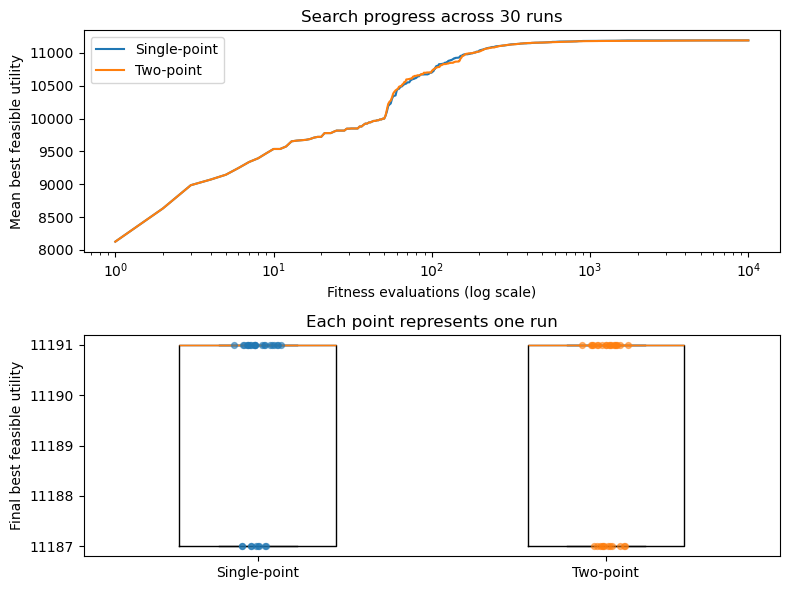

In [58]:
fig,axes=plt.subplots(2,1,figsize=(8,6))
score_groups=[]
positions=[1, 2]
plot_rng=np.random.default_rng(2026)

for position,(name, records) in zip(positions, runs.items()):
    histories = np.asarray([row["history"] for row in records])
    scores = np.asarray([row["score"] for row in records])
    evaluations = np.arange(1, histories.shape[1] + 1)

    axes[0].plot(evaluations, histories.mean(axis=0), label=name)
    score_groups.append(scores)

    offsets = plot_rng.uniform(-0.07, 0.07, size=len(scores))
    axes[1].scatter(position + offsets, scores, s=18, alpha=0.55, zorder=3)

axes[0].set_xscale("log")
axes[0].set_xlabel("Fitness evaluations (log scale)")
axes[0].set_ylabel("Mean best feasible utility")
axes[0].set_title("Search progress across 30 runs")
axes[0].legend()

axes[1].boxplot(score_groups, positions=positions, widths=0.45, showfliers=False)
axes[1].set_xticks(positions)
axes[1].set_xticklabels(list(runs))
axes[1].set_ylabel("Final best feasible utility")
axes[1].set_title("Each point represents one run")

plt.tight_layout()
plt.show()

### Reading the convergence curves and boxplots

The upper panel shows mean best feasible utility against fitness evaluations. The logarithmic horizontal axis makes early changes easier to see. The two curves follow similar paths and largely overlap, so the plot does not show a clear, sustained advantage for either crossover.

The lower panel shows the distribution of final scores. Each dot is one run; the horizontal offset separates overlapping dots and has no numerical meaning. Both variants had a median of 11,191 and a range of 11,187–11,191, which explains why their boxes look alike. The boxplots show the two distributions separately; the paired analysis below shows which method won when both started from the same seed.

## Results and discussion

| Measure | Single-point | Two-point |
|---|---:|---:|
| Feasible final solutions | 30/30 | 30/30 |
| Mean final utility | 11,189.80 | 11,189.40 |
| Median final utility | 11,191 | 11,191 |
| Minimum–maximum final utility | 11,187–11,191 | 11,187–11,191 |
| Mean infeasible children per run, before repair | 3,561.7 | 3,526.7 |
| Median runtime per run | 4.649 s | 4.636 s |

### Solution quality and hypothesis test

Single-point crossover won 7 paired runs, two-point crossover won 4, and 19 were ties. The most common outcome was therefore the same final utility. The mean paired difference, calculated as two-point minus single-point, was **−0.40 utility units**.

Only 11 of the 30 pairs had a winner. The two-sided exact sign test gave **p = 0.5488**, above the 0.05 significance level. I therefore do not reject the null hypothesis. The experiment does not support my prediction that two-point crossover wins more often. It also does not establish that the methods are equivalent: the many ties leave relatively few pairs to distinguish their win probabilities.

### Constraint handling and runtime

Each run evaluated 9,950 children after scoring the initial 50 individuals. Before repair, approximately 35.8% of single-point children and 35.4% of two-point children were infeasible. Two-point crossover therefore produced about 35 fewer infeasible children per run on average. Both variants nevertheless returned feasible final solutions in all 30 runs. The count measures how often a child violated capacity; it does not measure how many models were removed or how long repair took.

Median runtime was 4.649 seconds for single-point and 4.636 seconds for two-point, a difference of 0.013 seconds. This was a small observed difference, and I did not test runtime statistically. Single-point was always run first for each seed, so execution order is another reason not to claim a speed advantage.

### Conclusion

Under the same evaluation budget, two-point crossover produced slightly fewer infeasible children but did not improve final utility on average. Single-point had the higher sample mean, although the paired comparison did not establish a difference in win probability. These conclusions apply to this 90-model instance and these GA settings. Both variants used the same repair-and-refill strategy, so this experiment cannot isolate the effect of repair itself.

### References

Chu, P. C., & Beasley, J. E. (1998). A genetic algorithm for the multidimensional knapsack problem. *Journal of Heuristics, 4*, 63–86. [https://doi.org/10.1023/A:1009642405419](https://doi.org/10.1023/A:1009642405419)